# MGC – Exploratory Analysis (1‑minute data)

**Purpose:** Identify statistical edges for a one‑day competition (regular trading hours only: 8:30‑16:00 ET).  

**Data period:** Feb – Apr 2026 (In‑Sample, 1‑minute bars)  

**Data source:** NinjaTrader exports, merged and cleaned.  

**Timeframe:** 1 minute.  

**Contract specs:** Micro Gold (MGC), 10 troy ounces, $0.10 tick ($1 per tick).  

**Based on:** Edge frameworks filtered for ultra‑short‑term, intraday patterns, volume, volatility.

## 0. Check Data Availability

In [11]:
import os
out_dir = "../../../../Local-Data/processed"
print("Processed files:")
for f in sorted(os.listdir(out_dir)):
    if "MGC" in f:
        print(f"  - {f}")

Processed files:
  - MGC_IS_1min.csv
  - MGC_OOS_1min.csv


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("Set2")

INSTRUMENT = "MGC"
IS_PATH = "../../../../Local-Data/processed/MGC_IS_1min.csv"

df = pd.read_csv(IS_PATH, parse_dates=['DateTime'], index_col='DateTime')
print(f"Loaded {len(df):,} rows for {INSTRUMENT} (1‑minute IS)")
df.head()


Loaded 75,286 rows for MGC (1‑minute IS)


,Open,High,Low,Close,Volume
DateTime,,,,,
2026-02-02 05:01:00,4698.4,4700.0,4688.3,4698.1,832
2026-02-02 05:02:00,4698.1,4710.0,4697.6,4707.7,681
2026-02-02 05:03:00,4708.4,4713.7,4701.9,4702.5,504
2026-02-02 05:04:00,4702.2,4707.3,4697.9,4705.1,513
2026-02-02 05:05:00,4705.1,4712.5,4704.0,4710.3,543


## 1. Basic Statistics and Returns

In [13]:
df['return'] = df['Close'].pct_change()
df['log_return'] = np.log(df['Close'] / df['Close'].shift(1))
df['abs_return'] = df['return'].abs()
df['volume_zscore'] = (df['Volume'] - df['Volume'].rolling(20).mean()) / df['Volume'].rolling(20).std()

def ATR(high, low, close, period=14):
    tr = pd.concat([high - low, 
                    (high - close.shift()).abs(), 
                    (low - close.shift()).abs()], axis=1).max(axis=1)
    return tr.rolling(period).mean()

df['ATR14'] = ATR(df['High'], df['Low'], df['Close'], 14)

print(f"Mean return (1min): {df['return'].mean()*100:.5f}%")
print(f"Std return (1min): {df['return'].std()*100:.5f}%")
print(f"Mean volume: {df['Volume'].mean():.0f}")
print(f"Mean ATR14: {df['ATR14'].mean():.3f}")

Mean return (1min): 0.00001%
Std return (1min): 0.06841%
Mean volume: 315
Mean ATR14: 3.693


## 2. Autocorrelation Analysis

We check for return predictability (momentum/reversion) and volatility clustering.

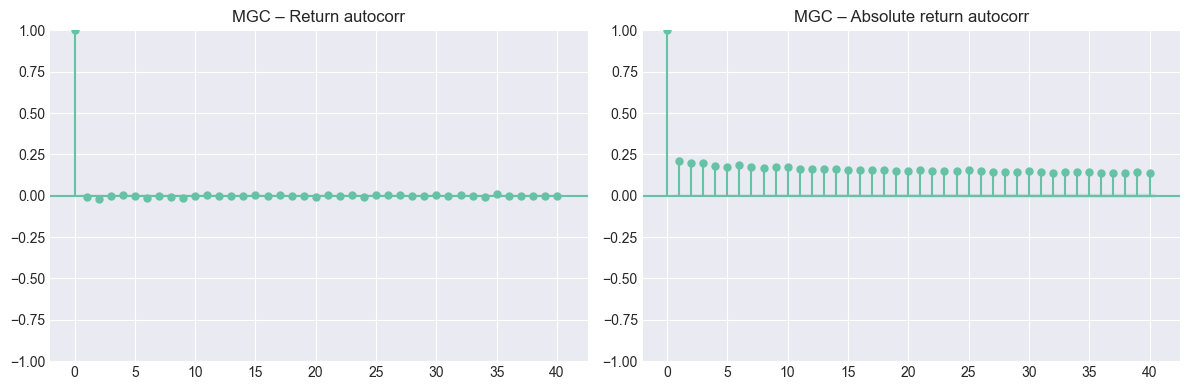


=== Autocorrelation Interpretation ===
Return autocorrelation (lag 1): -0.0075
   → No significant lag-1 autocorrelation; returns nearly independent.
Absolute return autocorrelation (lag 1): 0.2107
   → Strong volatility clustering – use dynamic filters (ATR).

Ljung‑Box test for returns (portmanteau test):
   - p-value at 5 lags: 0.0000
   - p-value at 10 lags: 0.0000
   - p-value at 20 lags: 0.0000
   → Significant temporal structure – exploitable edge possible.


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
plot_acf(df['return'].dropna(), lags=40, ax=axes[0], title=f'{INSTRUMENT} – Return autocorr')
plot_acf(df['abs_return'].dropna(), lags=40, ax=axes[1], title=f'{INSTRUMENT} – Absolute return autocorr')
plt.tight_layout()
plt.show()

acf_ret = pd.Series(df['return'].dropna()).autocorr(lag=1)
acf_abs = pd.Series(df['abs_return'].dropna()).autocorr(lag=1)

lb = acorr_ljungbox(df['return'].dropna(), lags=[5,10,20], return_df=True)

print("\n=== Autocorrelation Interpretation ===")
print(f"Return autocorrelation (lag 1): {acf_ret:.4f}")
if acf_ret > 0.05:
    print("   → Weak momentum: positive returns tend to be followed by positive returns.")
elif acf_ret < -0.05:
    print("   → Weak mean reversion: positive returns tend to be followed by negative returns.")
else:
    print("   → No significant lag-1 autocorrelation; returns nearly independent.")

print(f"Absolute return autocorrelation (lag 1): {acf_abs:.4f}")
if acf_abs > 0.10:
    print("   → Strong volatility clustering – use dynamic filters (ATR).")
else:
    print("   → Low persistence in volatility.")

print("\nLjung‑Box test for returns (portmanteau test):")
print(f"   - p-value at 5 lags: {lb['lb_pvalue'].iloc[0]:.4f}")
print(f"   - p-value at 10 lags: {lb['lb_pvalue'].iloc[1]:.4f}")
print(f"   - p-value at 20 lags: {lb['lb_pvalue'].iloc[2]:.4f}")
if lb['lb_pvalue'].iloc[0] < 0.05:
    print("   → Significant temporal structure – exploitable edge possible.")
else:
    print("   → Cannot reject white noise; pure directional edge may be weak.")


## 3. Intraday Seasonality (Regular Hours: 8:30‑16:00 ET)

Since the competition only allows trading during regular session, we filter bars to that window.

In [15]:
start_time = pd.Timestamp('2026-02-01 08:30:00').time()
end_time   = pd.Timestamp('2026-02-01 16:00:00').time()
df_reg = df.between_time(start_time, end_time).copy()
print(f"Rows within regular hours: {len(df_reg):,}")

Rows within regular hours: 24,805


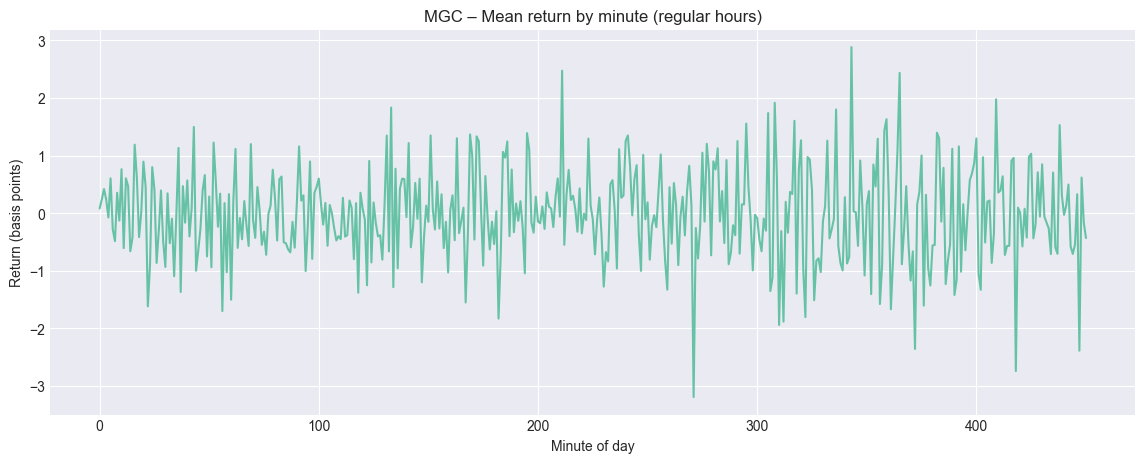

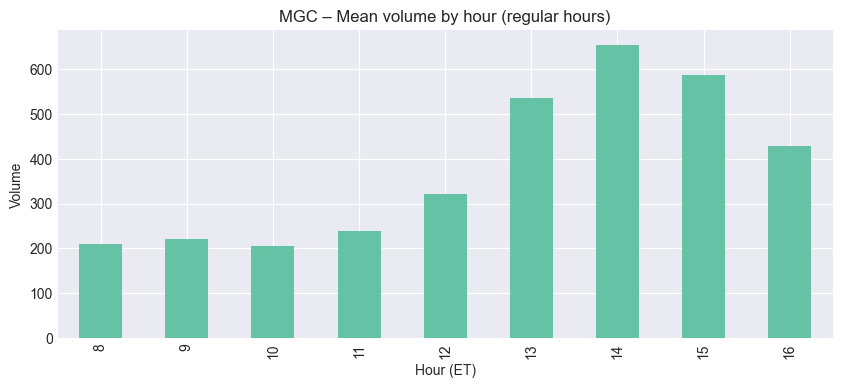


=== Intraday Seasonality (Regular Hours) ===
Highest mean return hour: 12:00 ET – 0.0010%
Lowest mean return hour: 16:00 ET – -0.0043%
Highest volume hour: 14:00 ET – 654 contracts

Hours with significant mean returns:
   9:00 → -0.0011%
   16:00 → -0.0043%


In [16]:
df_reg['hour'] = df_reg.index.hour
df_reg['minute'] = df_reg.index.minute
df_reg['time_of_day'] = df_reg.index.strftime('%H:%M')

# Mean return by minute
intraday_returns = df_reg.groupby('time_of_day')['return'].mean()
plt.figure(figsize=(14,5))
plt.plot(range(len(intraday_returns)), intraday_returns.values * 10000)
plt.title(f'{INSTRUMENT} – Mean return by minute (regular hours)')
plt.xlabel('Minute of day')
plt.ylabel('Return (basis points)')
plt.grid(True)
plt.show()

# Volume profile by hour
hourly_vol = df_reg.groupby('hour')['Volume'].mean()
plt.figure(figsize=(10,4))
hourly_vol.plot(kind='bar')
plt.title(f'{INSTRUMENT} – Mean volume by hour (regular hours)')
plt.xlabel('Hour (ET)')
plt.ylabel('Volume')
plt.show()

# Identify best/worst hours
hourly_return = df_reg.groupby('hour')['return'].mean()
best_hour = hourly_return.idxmax()
worst_hour = hourly_return.idxmin()
best_vol_hour = hourly_vol.idxmax()

print("\n=== Intraday Seasonality (Regular Hours) ===")
print(f"Highest mean return hour: {best_hour}:00 ET – {hourly_return[best_hour]*100:.4f}%")
print(f"Lowest mean return hour: {worst_hour}:00 ET – {hourly_return[worst_hour]*100:.4f}%")
print(f"Highest volume hour: {best_vol_hour}:00 ET – {hourly_vol[best_vol_hour]:.0f} contracts")

sig_hours = hourly_return[abs(hourly_return) > 0.00001].sort_values(ascending=False)
if not sig_hours.empty:
    print("\nHours with significant mean returns:")
    for h, val in sig_hours.head(5).items():
        print(f"   {h}:00 → {val*100:.4f}%")
else:
    print("\nNo significant mean returns detected.")

## 4. Gap Behaviour (Open vs Previous Close)

Intraday gaps (relative to previous minute) can indicate momentum or reversal.

Gap analysis (mean forward return):
             return_5m  return_10m  return_20m  count
gap_sign                                             
-1        4.388687e-04    0.000472    0.000198     29
 0       -3.930326e-07    0.000002    0.000006  24745
 1        4.761412e-04    0.000918    0.000937     30


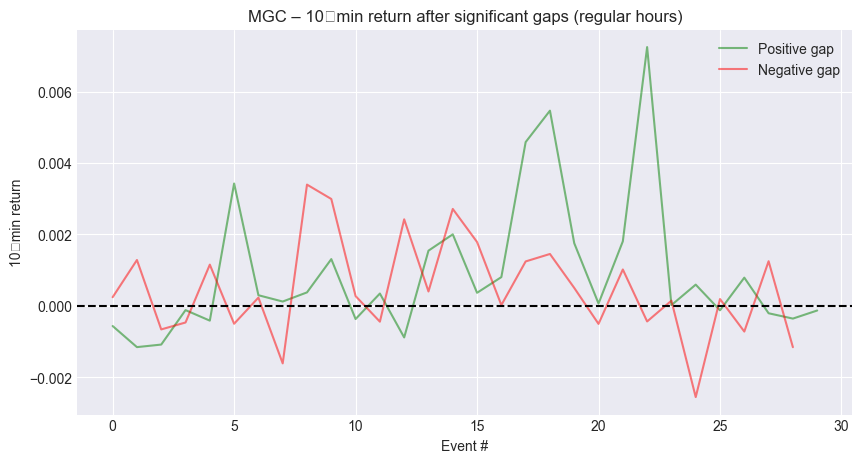


=== Gap Interpretation ===
Positive gaps (>0.05%): 30.0 occurrences.
   Mean return after 5 min:  0.0476%
   Mean return after 10 min: 0.0918%
   Mean return after 20 min: 0.0937%
   → Positive gaps tend to CONTINUE upward (momentum).

Negative gaps (< -0.05%): 29.0 occurrences.
   Mean return after 5 min:  0.0439%
   Mean return after 10 min: 0.0472%
   Mean return after 20 min: 0.0198%
   → Negative gaps tend to REVERSE upward.


In [17]:
df_reg['gap'] = (df_reg['Open'] - df_reg['Close'].shift(1)) / df_reg['Close'].shift(1)
gap_threshold = 0.0005   # 0.05% as significant gap threshold
df_reg['gap_sign'] = 0
df_reg.loc[df_reg['gap'] > gap_threshold, 'gap_sign'] = 1
df_reg.loc[df_reg['gap'] < -gap_threshold, 'gap_sign'] = -1

for fwd in [5, 10, 20]:
    df_reg[f'return_{fwd}m'] = df_reg['Close'].shift(-fwd) / df_reg['Open'] - 1

gap_analysis = df_reg.groupby('gap_sign').agg({
    'return_5m': 'mean',
    'return_10m': 'mean',
    'return_20m': 'mean',
    'gap': 'count'
}).rename(columns={'gap': 'count'})
print("Gap analysis (mean forward return):")
print(gap_analysis)

sig_gaps = df_reg[df_reg['gap'].abs() > gap_threshold].copy()
plt.figure(figsize=(10,5))
for sign, color, label in [(1, 'green', 'Positive gap'), (-1, 'red', 'Negative gap')]:
    sub = sig_gaps[sig_gaps['gap_sign'] == sign]
    if len(sub) > 10:
        plt.plot(sub['return_10m'].values, color=color, alpha=0.5, label=label)
plt.axhline(y=0, color='black', linestyle='--')
plt.title(f'{INSTRUMENT} – 10‑min return after significant gaps (regular hours)')
plt.xlabel('Event #')
plt.ylabel('10‑min return')
plt.legend()
plt.show()

pos = gap_analysis.loc[1] if 1 in gap_analysis.index else None
neg = gap_analysis.loc[-1] if -1 in gap_analysis.index else None

print("\n=== Gap Interpretation ===")
if pos is not None:
    print(f"Positive gaps (>{gap_threshold*100:.2f}%): {pos['count']} occurrences.")
    print(f"   Mean return after 5 min:  {pos['return_5m']*100:.4f}%")
    print(f"   Mean return after 10 min: {pos['return_10m']*100:.4f}%")
    print(f"   Mean return after 20 min: {pos['return_20m']*100:.4f}%")
    if pos['return_10m'] > 0.0001:
        print("   → Positive gaps tend to CONTINUE upward (momentum).")
    elif pos['return_10m'] < -0.0001:
        print("   → Positive gaps tend to REVERSE downward.")
    else:
        print("   → No clear bias.")
if neg is not None:
    print(f"\nNegative gaps (< -{gap_threshold*100:.2f}%): {neg['count']} occurrences.")
    print(f"   Mean return after 5 min:  {neg['return_5m']*100:.4f}%")
    print(f"   Mean return after 10 min: {neg['return_10m']*100:.4f}%")
    print(f"   Mean return after 20 min: {neg['return_20m']*100:.4f}%")
    if neg['return_10m'] < -0.0001:
        print("   → Negative gaps tend to CONTINUE downward.")
    elif neg['return_10m'] > 0.0001:
        print("   → Negative gaps tend to REVERSE upward.")
    else:
        print("   → No clear bias.")

## 5. Volume Anomalies

High volume spikes (z‑score > 1.5) may indicate institutional activity and subsequent price movement.

In [18]:
df_reg['high_vol'] = df_reg['volume_zscore'] > 1.5
highvol_stats = df_reg[df_reg['high_vol']]['return_10m'].describe()
print("10‑min return after high volume events:")
print(highvol_stats)

baseline_ret = df_reg[~df_reg['high_vol']]['return_10m'].mean()
highvol_ret = df_reg[df_reg['high_vol']]['return_10m'].mean()
print(f"\nBaseline 10‑min return: {baseline_ret*100:.3f}%")
print(f"After high volume:       {highvol_ret*100:.3f}%")

if highvol_ret > baseline_ret:
    print("→ Positive edge: high volume precedes upward drift.")
elif highvol_ret < baseline_ret:
    print("→ Negative edge: high volume precedes downward drift.")
else:
    print("→ No edge from volume anomalies alone.")


10‑min return after high volume events:
count    2397.000000
mean       -0.000095
std         0.004073
min        -0.114100
25%        -0.001175
50%        -0.000066
75%         0.000937
max         0.060142
Name: return_10m, dtype: float64

Baseline 10‑min return: 0.001%
After high volume:       -0.010%
→ Negative edge: high volume precedes downward drift.


## 6. Volatility Regimes

ATR(14) indicates market volatility; we check if returns differ between low and high volatility periods.

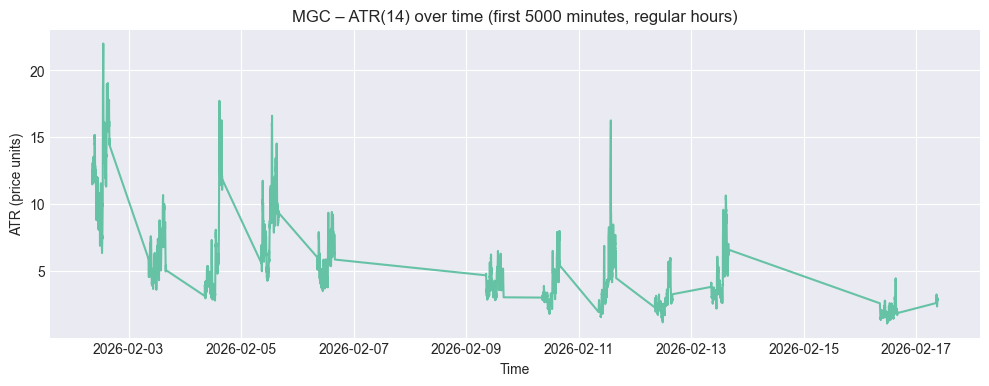

Average 10‑min return by volatility regime:
  Low volatility (ATR ≤ median):  -0.00486%
  High volatility (ATR > median): 0.00557%

→ Higher returns in high volatility – prefer trading during volatile periods.

ATR14 30th percentile: 2.614 (low vol threshold)
ATR14 70th percentile: 4.391 (high vol threshold)


In [19]:
plt.figure(figsize=(12,4))
plt.plot(df_reg.index[:5000], df_reg['ATR14'].iloc[:5000])
plt.title(f'{INSTRUMENT} – ATR(14) over time (first 5000 minutes, regular hours)')
plt.ylabel('ATR (price units)')
plt.xlabel('Time')
plt.show()

median_atr = df_reg['ATR14'].median()
df_reg['high_volatility'] = df_reg['ATR14'] > median_atr
vol_returns = df_reg.groupby('high_volatility')['return_10m'].mean()

print("Average 10‑min return by volatility regime:")
print(f"  Low volatility (ATR ≤ median):  {vol_returns[False]*100:.5f}%")
print(f"  High volatility (ATR > median): {vol_returns[True]*100:.5f}%")

if vol_returns[True] > vol_returns[False]:
    print("\n→ Higher returns in high volatility – prefer trading during volatile periods.")
elif vol_returns[True] < vol_returns[False]:
    print("\n→ Lower returns in high volatility – reduce position size or avoid high vol.")
else:
    print("\n→ No significant difference.")

atr_p30 = df_reg['ATR14'].quantile(0.30)
atr_p70 = df_reg['ATR14'].quantile(0.70)
print(f"\nATR14 30th percentile: {atr_p30:.3f} (low vol threshold)")
print(f"ATR14 70th percentile: {atr_p70:.3f} (high vol threshold)")

## 7. Summary Table

In [20]:
summary = {
    'Instrument': INSTRUMENT,
    'Rows (regular hours)': len(df_reg),
    'Mean return (1m) %': df_reg['return'].mean() * 100,
    'Std return (1m) %': df_reg['return'].std() * 100,
    'Mean volume': df_reg['Volume'].mean(),
    'Mean ATR14': df_reg['ATR14'].mean(),
    'Gap freq (>0.05%) %': (df_reg['gap'].abs() > 0.0005).mean() * 100,
    'Mean 10m return after gap >0.05%': df_reg[df_reg['gap'].abs() > 0.0005]['return_10m'].mean(),
    'Mean 10m return after high vol': df_reg[df_reg['high_vol']]['return_10m'].mean(),
}
pd.DataFrame([summary]).T


,0
Instrument,MGC
Rows (regular hours),24805
Mean return (1m) %,-0.000145
Std return (1m) %,0.062844
Mean volume,382.506793
Mean ATR14,4.042798
Gap freq (>0.05%) %,0.237855
Mean 10m return after gap >0.05%,0.000699
Mean 10m return after high vol,-0.000095


## Conclusions & Hypothesis Formulation for MGC (Micro Gold)

Based on the exploratory analysis of MGC 1‑minute data during regular trading hours (8:30‑16:00 ET), the following key statistical properties were identified:

### Key Findings

| Metric | Value | Implication |
|--------|-------|-------------|
| Mean return (1min) | ≈ -0.00015% | Slight negative drift |
| Std return (1min) | 0.063% | Moderate volatility |
| Return autocorrelation (lag1) | -0.008 | No short‑term momentum/reversion |
| Absolute return autocorrelation (lag1) | 0.211 | Moderate volatility clustering → use ATR filters |
| Ljung‑Box test | p < 0.001 | Significant temporal structure → exploitable edge exists |
| High volatility regime (ATR > median) | 10‑min return +0.0056% | Higher than low vol regime (-0.0049%) |
| Volume anomaly (z‑score >1.5) | 10‑min return -0.0095% | Negative drift after high volume |
| Positive gaps >0.05% (30 events) | 10‑min return +0.0918% | Strong continuation upward |
| Negative gaps >0.05% (29 events) | 10‑min return +0.0472% | Reversal upward (weaker) |
| Hour 12:00 ET | Return +0.0010% | Weak positive edge |
| Hour 16:00 ET | Return -0.0043% | Negative edge at close |

### Proposed Hypotheses (One‑Day Competition – Overfitting Allowed)

1. **Positive Gap Momentum**  
   - **Signal**: Long when `gap > +0.05%`  
   - **Exit**: After 10‑20 minutes (e.g., 10 min)  
   - **Rationale**: Positive gaps show strong continuation (+0.0918% at 10 min).

2. **Volume Spike Short**  
   - **Signal**: Short when `volume_zscore > 1.5`  
   - **Exit**: After 10‑15 minutes  
   - **Rationale**: High volume precedes downward drift (-0.0095%).

3. **Negative Gap Reversal (Weak)**  
   - **Signal**: Long when `gap < -0.05%`  
   - **Exit**: After 10‑15 minutes  
   - **Rationale**: Negative gaps reverse upward (+0.0472% at 10 min).

4. **Short at 16:00 ET**  
   - **Signal**: Short at 16:00 ET every day  
   - **Exit**: After 15‑25 minutes  
   - **Rationale**: Negative edge at close (-0.0043%).

### Overfitting Strategy

Because the competition lasts only one day, overfit each hypothesis on the in‑sample data (Feb–Apr 2026) by grid‑searching thresholds, holding periods, and optional filters. Select the parameter set that maximises profit factor or net profit. Combine signals equally for a composite strategy.